In [1]:
pip install pandas numpy scikit-learn pgmpy matplotlib networkx

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 9.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [pgmpy]


In [2]:

import numpy as np
import pandas as pd

# Reproducible synthetic dataset
rng = np.random.default_rng(42)
N = 2000

traffic = rng.choice(
    ["Low", "Medium", "High"], N,
    p=[0.50, 0.32, 0.18]
)

failed_logins = []
packet_rate = []
protocol = []
port_risk = []
ip_reputation = []
attack = []

for i in range(N):
    # Failed login attempts depend partly on traffic volume
    login_probs = {
        "Low": [0.80, 0.17, 0.03],
        "Medium": [0.55, 0.30, 0.15],
        "High": [0.30, 0.35, 0.35]
    }
    login = rng.choice(
        ["Low", "Medium", "High"],
        p=login_probs[traffic[i]]
    )

    # Packet rate depends partly on traffic volume
    packet_probs = {
        "Low": [0.80, 0.17, 0.03],
        "Medium": [0.15, 0.65, 0.20],
        "High": [0.05, 0.25, 0.70]
    }
    packet = rng.choice(
        ["Low", "Medium", "High"],
        p=packet_probs[traffic[i]]
    )

    proto = rng.choice(
        ["TCP", "UDP", "ICMP"],
        p=[0.65, 0.28, 0.07]
    )

    port = rng.choice(
        ["Low", "Medium", "High"],
        p=[0.45, 0.35, 0.20]
    )

    # Source IP reputation
    reputation = rng.choice(
        ["Good", "Suspicious", "Malicious"],
        p=[0.78, 0.16, 0.06]
    )

    # Simulated attack probability
    score = -3.0

    score += {
        "Low": 0.0,
        "Medium": 0.5,
        "High": 1.1
    }[traffic[i]]

    score += {
        "Low": 0.0,
        "Medium": 0.8,
        "High": 1.8
    }[login]

    score += {
        "Low": 0.0,
        "Medium": 0.4,
        "High": 1.0
    }[packet]

    score += {
        "Low": 0.0,
        "Medium": 0.5,
        "High": 1.0
    }[port]

    score += {
        "Good": 0.0,
        "Suspicious": 1.0,
        "Malicious": 2.2
    }[reputation]

    score += {
        "TCP": 0.2,
        "UDP": 0.3,
        "ICMP": 0.7
    }[proto]

    probability = 1 / (1 + np.exp(-score))
    event = rng.random() < probability

    failed_logins.append(login)
    packet_rate.append(packet)
    protocol.append(proto)
    port_risk.append(port)
    ip_reputation.append(reputation)
    attack.append("Yes" if event else "No")

df = pd.DataFrame({
    "Traffic_Volume": traffic,
    "Failed_Logins": failed_logins,
    "Packet_Rate": packet_rate,
    "Protocol": protocol,
    "Port_Risk": port_risk,
    "IP_Reputation": ip_reputation,
    "Attack": attack
})

df.to_csv("synthetic_intrusion_dataset.csv", index=False)

print("Dataset created successfully!")
print("Shape:", df.shape)
print("\nFirst 10 records:")
print(df.head(10))
print("\nAttack distribution:")
print(df["Attack"].value_counts())
print("\nAttack proportions:")
print(df["Attack"].value_counts(normalize=True).round(3))


Dataset created successfully!
Shape: (2000, 7)

First 10 records:
  Traffic_Volume Failed_Logins Packet_Rate Protocol Port_Risk IP_Reputation  \
0         Medium        Medium      Medium     ICMP    Medium          Good   
1            Low           Low         Low      TCP    Medium          Good   
2           High           Low        High      TCP    Medium          Good   
3         Medium        Medium      Medium      UDP       Low          Good   
4            Low           Low         Low      UDP       Low          Good   
5           High           Low        High      TCP       Low          Good   
6         Medium          High         Low      TCP    Medium          Good   
7         Medium        Medium        High     ICMP       Low          Good   
8            Low           Low         Low     ICMP       Low          Good   
9            Low           Low         Low     ICMP    Medium          Good   

  Attack  
0     No  
1     No  
2    Yes  
3    Yes  
4     No 

In [3]:
pip install pandas numpy scikit-learn pgmpy matplotlib seaborn networkx

DATASET OVERVIEW

First five rows:
  Traffic_Volume Failed_Logins Packet_Rate Protocol Port_Risk IP_Reputation  \
0         Medium        Medium      Medium     ICMP    Medium          Good   
1            Low           Low         Low      TCP    Medium          Good   
2           High           Low        High      TCP    Medium          Good   
3         Medium        Medium      Medium      UDP       Low          Good   
4            Low           Low         Low      UDP       Low          Good   

  Attack  
0     No  
1     No  
2    Yes  
3    Yes  
4     No  

Dataset shape: (2000, 7)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   Traffic_Volume  2000 non-null   object
 1   Failed_Logins   2000 non-null   object
 2   Packet_Rate     2000 non-null   object
 3   Protocol        2000 non-null   object
 4   P

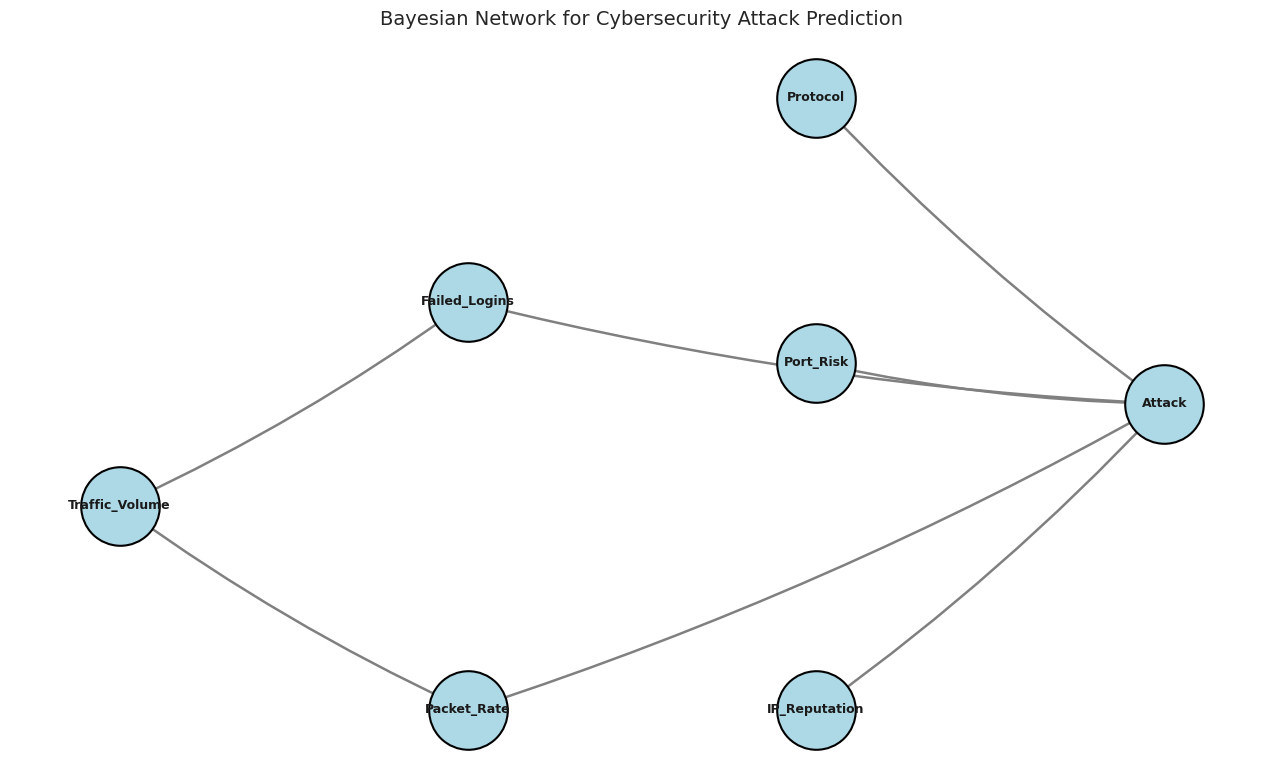


ATTACK PROBABILITY ESTIMATION

Evidence supplied:
Traffic_Volume: High
Failed_Logins: High
Packet_Rate: High
Protocol: TCP
Port_Risk: High
IP_Reputation: Malicious

Probability distribution:
Outcome  Probability
     No          0.5
    Yes          0.5
P(Attack=No | evidence) = 0.5000 (50.00%)
P(Attack=Yes | evidence) = 0.5000 (50.00%)


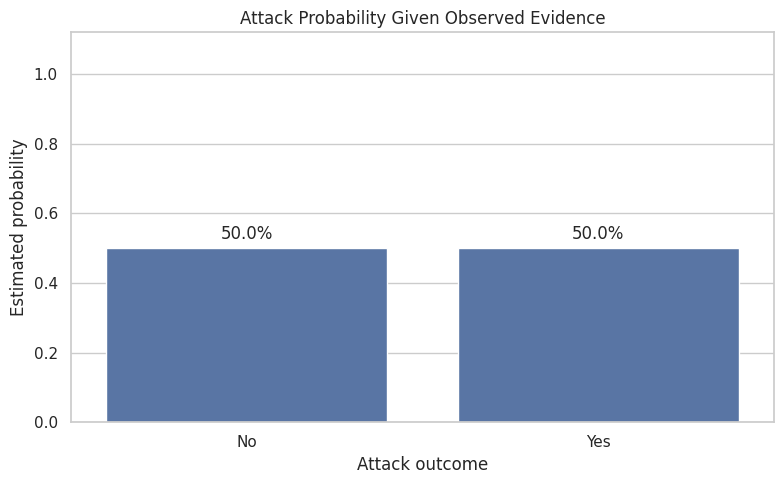


MODEL EVALUATION
Accuracy:  0.7250
Precision: 0.6389
Recall:    0.3538
F1-score:  0.4554
Log loss:  0.5991

Classification report:
              precision    recall  f1-score   support

          No       0.74      0.90      0.82       270
         Yes       0.64      0.35      0.46       130

    accuracy                           0.72       400
   macro avg       0.69      0.63      0.64       400
weighted avg       0.71      0.72      0.70       400



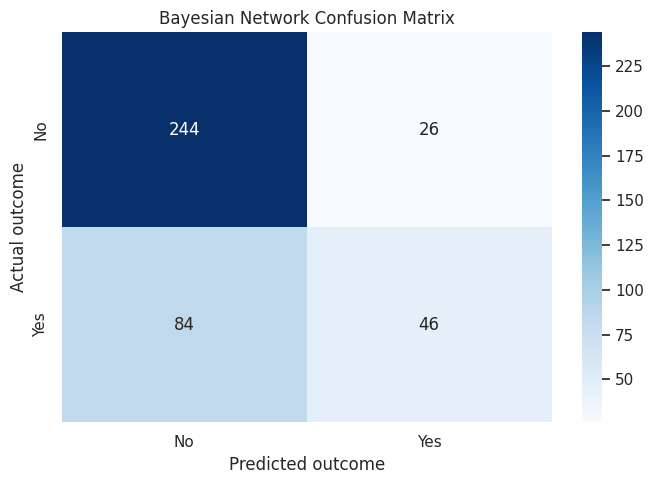

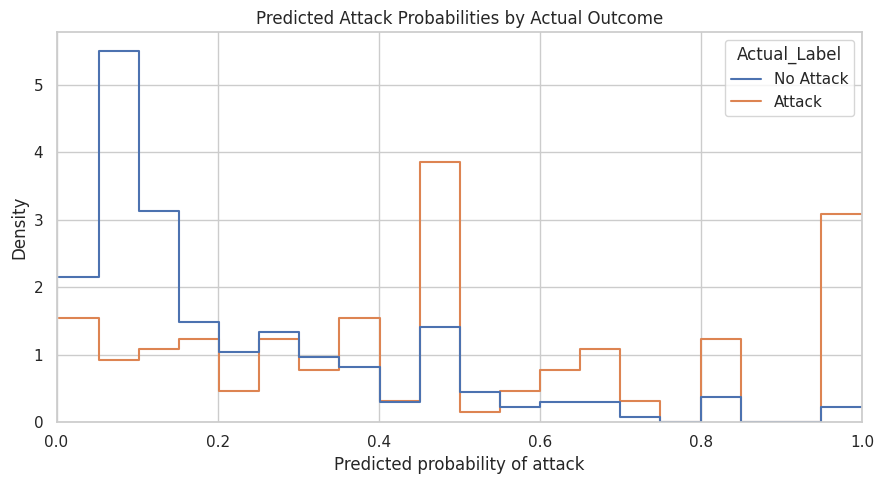


ANALYSIS COMPLETED

Results saved in: bayesian_results/

Generated files:
- 1_bayesian_network.png
- 2_attack_probability.png
- 3_confusion_matrix.png
- 4_probability_distribution.png
- attack_probability_result.csv
- model_metrics.csv
- test_predictions.csv


In [5]:

# ============================================================
# BAYESIAN NETWORK FOR CYBERSECURITY ATTACK PROBABILITY
# ============================================================

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    log_loss
)

from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.estimators import BayesianEstimator
from pgmpy.inference import VariableElimination

warnings.filterwarnings("ignore", category=FutureWarning)

RANDOM_STATE = 42
DATASET_PATH = "synthetic_intrusion_dataset.csv"
OUTPUT_DIR = "bayesian_results"

os.makedirs(OUTPUT_DIR, exist_ok=True)

sns.set_theme(style="whitegrid")

# ============================================================
# 1. LOAD DATASET
# ============================================================

df = pd.read_csv(DATASET_PATH)

print("=" * 60)
print("DATASET OVERVIEW")
print("=" * 60)

print("\nFirst five rows:")
print(df.head())

print("\nDataset shape:", df.shape)

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

# ============================================================
# 2. SELECT FEATURES AND TARGET
# ============================================================

features = [
    "Traffic_Volume",
    "Failed_Logins",
    "Packet_Rate",
    "Protocol",
    "Port_Risk",
    "IP_Reputation"
]

target = "Attack"

required_columns = features + [target]

missing_columns = [
    col for col in required_columns if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Dataset is missing required columns: {missing_columns}"
    )

data = df[required_columns].dropna().copy()

for column in required_columns:
    data[column] = data[column].astype(str)

if data[target].nunique() < 2:
    raise ValueError("The target must contain at least two classes.")

print("\nTarget distribution:")
print(data[target].value_counts())

print("\nTarget proportions:")
print(data[target].value_counts(normalize=True).round(4))

# ============================================================
# 3. SPLIT INTO TRAINING AND TEST DATA
# ============================================================

train, test = train_test_split(
    data,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=data[target]
)

print("\nTraining records:", len(train))
print("Testing records:", len(test))

# ============================================================
# 4. DEFINE BAYESIAN NETWORK STRUCTURE
# ============================================================

edges = [
    ("Traffic_Volume", "Failed_Logins"),
    ("Traffic_Volume", "Packet_Rate"),
    ("Failed_Logins", "Attack"),
    ("Packet_Rate", "Attack"),
    ("Protocol", "Attack"),
    ("Port_Risk", "Attack"),
    ("IP_Reputation", "Attack")
]

model = DiscreteBayesianNetwork(edges)

# Preserve all categories, including categories that might not
# occur in a particular training split.
state_names = {
    column: sorted(data[column].unique().tolist())
    for column in required_columns
}

# ============================================================
# 5. LEARN CONDITIONAL PROBABILITY TABLES
# ============================================================

estimator = BayesianEstimator(
    model,
    train,
    state_names=state_names
)

cpds = estimator.get_parameters(
    prior_type="BDeu",
    equivalent_sample_size=5
)

model.add_cpds(*cpds)

if not model.check_model():
    raise ValueError("Bayesian Network validation failed.")

print("\n" + "=" * 60)
print("BAYESIAN NETWORK TRAINED SUCCESSFULLY")
print("=" * 60)

print("\nNetwork edges:")
print(list(model.edges()))

print("\nConditional Probability Distributions:")

for cpd in model.get_cpds():
    print("\n", cpd)

# ============================================================
# 6. GRAPH 1: BAYESIAN NETWORK STRUCTURE
# ============================================================

plt.figure(figsize=(13, 8))

G = nx.DiGraph()
G.add_edges_from(model.edges())

pos = {
    "Traffic_Volume": (0, 2),
    "Failed_Logins": (2, 3),
    "Packet_Rate": (2, 1),
    "Protocol": (4, 4),
    "Port_Risk": (4, 2.7),
    "IP_Reputation": (4, 1),
    "Attack": (6, 2.5)
}

nx.draw_networkx_nodes(
    G,
    pos,
    node_size=3200,
    node_color="lightblue",
    edgecolors="black",
    linewidths=1.5
)

nx.draw_networkx_labels(
    G,
    pos,
    font_size=9,
    font_weight="bold"
)

nx.draw_networkx_edges(
    G,
    pos,
    arrows=True,
    arrowsize=22,
    width=1.8,
    edge_color="gray",
    connectionstyle="arc3,rad=0.05"
)

plt.title(
    "Bayesian Network for Cybersecurity Attack Prediction",
    fontsize=14
)
plt.axis("off")
plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/1_bayesian_network.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 7. ESTIMATE ATTACK PROBABILITY USING EVIDENCE
# ============================================================

inference = VariableElimination(model)

# Example scenario: suspicious network activity
evidence = {
    "Traffic_Volume": "High",
    "Failed_Logins": "High",
    "Packet_Rate": "High",
    "Protocol": "TCP",
    "Port_Risk": "High",
    "IP_Reputation": "Malicious"
}

# Validate evidence values against the observed states.
for variable, value in evidence.items():
    if value not in state_names[variable]:
        raise ValueError(
            f"Invalid state {value!r} for {variable}. "
            f"Valid states: {state_names[variable]}"
        )

result = inference.query(
    variables=[target],
    evidence=evidence,
    show_progress=False
)

outcomes = list(result.state_names[target])
probabilities = np.asarray(result.values).ravel()

probability_df = pd.DataFrame({
    "Outcome": outcomes,
    "Probability": probabilities
})

print("\n" + "=" * 60)
print("ATTACK PROBABILITY ESTIMATION")
print("=" * 60)

print("\nEvidence supplied:")
for variable, value in evidence.items():
    print(f"{variable}: {value}")

print("\nProbability distribution:")
print(probability_df.to_string(index=False))

for outcome, probability in zip(outcomes, probabilities):
    print(
        f"P(Attack={outcome} | evidence) = "
        f"{probability:.4f} ({probability * 100:.2f}%)"
    )

# ============================================================
# 8. GRAPH 2: EVENT PROBABILITY
# ============================================================

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=probability_df,
    x="Outcome",
    y="Probability"
)

ax.set_ylim(0, 1.12)
ax.set_xlabel("Attack outcome")
ax.set_ylabel("Estimated probability")
ax.set_title("Attack Probability Given Observed Evidence")

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f%%",
        labels=[
            f"{value * 100:.1f}%"
            for value in probabilities
        ],
        padding=4
    )

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/2_attack_probability.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 9. PREDICT ATTACK PROBABILITIES ON TEST DATA
# ============================================================

y_true = test[target].reset_index(drop=True)

predictions = []
attack_probabilities = []

for _, row in test.iterrows():

    case_evidence = {
        column: row[column]
        for column in features
    }

    prediction_result = inference.query(
        variables=[target],
        evidence=case_evidence,
        show_progress=False
    )

    prediction_states = list(
        prediction_result.state_names[target]
    )

    prediction_probs = np.asarray(
        prediction_result.values
    ).ravel()

    # Select the most probable outcome
    predicted_index = int(np.argmax(prediction_probs))
    predictions.append(prediction_states[predicted_index])

    # Save P(Attack = Yes) for probability evaluation
    yes_index = prediction_states.index("Yes")
    attack_probabilities.append(prediction_probs[yes_index])

y_pred = np.array(predictions)
y_prob = np.array(attack_probabilities)

# ============================================================
# 10. MODEL EVALUATION
# ============================================================

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(
    y_true, y_pred, pos_label="Yes", zero_division=0
)
recall = recall_score(
    y_true, y_pred, pos_label="Yes", zero_division=0
)
f1 = f1_score(
    y_true, y_pred, pos_label="Yes", zero_division=0
)

# Binary log loss, with labels explicitly ordered
binary_y = (y_true == "Yes").astype(int)

epsilon = 1e-15
clipped_probs = np.clip(y_prob, epsilon, 1 - epsilon)

probability_log_loss = log_loss(
    binary_y,
    clipped_probs,
    labels=[0, 1]
)

print("\n" + "=" * 60)
print("MODEL EVALUATION")
print("=" * 60)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")
print(f"Log loss:  {probability_log_loss:.4f}")

print("\nClassification report:")
print(
    classification_report(
        y_true,
        y_pred,
        labels=["No", "Yes"],
        zero_division=0
    )
)

# ============================================================
# 11. GRAPH 3: CONFUSION MATRIX
# ============================================================

labels = ["No", "Yes"]

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=labels
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.xlabel("Predicted outcome")
plt.ylabel("Actual outcome")
plt.title("Bayesian Network Confusion Matrix")

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/3_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 12. GRAPH 4: PREDICTED PROBABILITIES VS ACTUAL OUTCOMES
# ============================================================

evaluation_df = pd.DataFrame({
    "Actual": binary_y.to_numpy(),
    "Predicted_Probability": y_prob
})

evaluation_df["Actual_Label"] = evaluation_df["Actual"].map({
    0: "No Attack",
    1: "Attack"
})

plt.figure(figsize=(9, 5))

sns.histplot(
    data=evaluation_df,
    x="Predicted_Probability",
    hue="Actual_Label",
    bins=20,
    stat="density",
    common_norm=False,
    element="step",
    fill=False
)

plt.xlim(0, 1)
plt.xlabel("Predicted probability of attack")
plt.ylabel("Density")
plt.title("Predicted Attack Probabilities by Actual Outcome")

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/4_probability_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 13. SAVE RESULTS
# ============================================================

probability_df.to_csv(
    f"{OUTPUT_DIR}/attack_probability_result.csv",
    index=False
)

test_results = test.reset_index(drop=True).copy()
test_results["Predicted_Attack"] = y_pred
test_results["Probability_Attack_Yes"] = y_prob

test_results.to_csv(
    f"{OUTPUT_DIR}/test_predictions.csv",
    index=False
)

metrics_df = pd.DataFrame([{
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1_Score": f1,
    "Log_Loss": probability_log_loss
}])

metrics_df.to_csv(
    f"{OUTPUT_DIR}/model_metrics.csv",
    index=False
)

print("\n" + "=" * 60)
print("ANALYSIS COMPLETED")
print("=" * 60)

print(f"\nResults saved in: {OUTPUT_DIR}/")

print("\nGenerated files:")
for filename in sorted(os.listdir(OUTPUT_DIR)):
    print("-", filename)
